### 03. Testes de H1 e H2

**Etapa CRISP-DM:** modelagem (análise explicativa).

- **H1:** domicílios que receberam campanha têm menor inativação, controlando por RFM.
- **H2:** domicílios que resgataram cupom têm menor inativação, com o mesmo controle.
- **Critério de refutação (Fase 1):** sem diferença significativa a 5%.

**Desenho:** análise principal no corte de treino com 8 semanas; replicação no corte de teste; sensibilidade com 4 e 12 semanas; moderação por renda e tamanho na subamostra com demografia.

**Leitura:** as campanhas não foram sorteadas. Os resultados são associações controladas por RFM, não efeitos causais.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = RAIZ / "reports" / "hipoteses"; REP.mkdir(parents=True, exist_ok=True)
FIG = RAIZ / "reports" / "figuras"
base = pd.read_csv(RAIZ / "data" / "processed" / "base_modelagem.csv")
base = base[base.corte != "score"].copy()
# log1p = log(1 + x): reduz a assimetria de frequência e gasto (poucos clientes gastam muito)
base["log_freq"] = np.log1p(base["frequencia"])
base["log_monetario"] = np.log1p(base["monetario"])
base["recencia_sem"] = base["recencia_dias"] / 7
NUM = {}
base.groupby("corte").size()

corte
teste     2417
treino    2409
dtype: int64

#### 1. Comparação bruta (qui-quadrado)
Taxa de inativação de quem foi exposto e de quem não foi, sem nenhum controle.

In [2]:
def bruta(df, x, y="inativo_8s"):
    d = df[[x, y]].dropna()
    tab = pd.crosstab(d[x], d[y])
    chi2, p, _, _ = chi2_contingency(tab)
    taxa = d.groupby(x)[y].mean().mul(100).round(1)
    return {"variavel": x, "n_0": int((d[x] == 0).sum()), "n_1": int((d[x] == 1).sum()),
            "inativ_pct_0": float(taxa.get(0)), "inativ_pct_1": float(taxa.get(1)),
            "chi2": round(float(chi2), 2), "p_valor": float(p)}
tr = base[base.corte == "treino"]
brutas = pd.DataFrame([bruta(tr, "recebeu_campanha"), bruta(tr, "resgatou_cupom")])
NUM["bruta_treino_8s"] = brutas.to_dict("records")
brutas

,variavel,n_0,n_1,inativ_pct_0,inativ_pct_1,chi2,p_valor
0,recebeu_campanha,1021,1388,17.0,2.8,146.08,1.247418e-33
1,resgatou_cupom,2112,297,10.0,0.3,29.21,6.488135e-08


#### 2. Multicolinearidade dos controles (VIF)
VIF acima de 5 indica que a variável é quase uma combinação das outras e deixa os coeficientes instáveis.

In [3]:
# O fator de inflação da variância mede o quanto cada variável é explicada pelas outras
def vif(df, cols):
    X = df[cols].assign(const=1.0)
    return pd.Series({c: round(variance_inflation_factor(X.values, i), 2) for i, c in enumerate(cols)})
cand = ["recencia_sem", "log_freq", "log_monetario", "recebeu_campanha", "resgatou_cupom"]
v = vif(tr, cand)
NUM["vif_treino"] = v.to_dict()
v

recencia_sem        1.61
log_freq            4.25
log_monetario       4.17
recebeu_campanha    1.67
resgatou_cupom      1.17
dtype: float64

#### 3. Regressão logística com RFM de controle
Razão de chance (OR) menor que 1 = associação com **menor** chance de inativação.

In [4]:
# controle por RFM: recência (semanas), frequência e valor (em log)
CONTROLE = "recencia_sem + log_freq + log_monetario"

def logit_or(df, var, y="inativo_8s", extra=""):
    d = df.dropna(subset=[y]).copy(); d[y] = d[y].astype(int)
    # statsmodels: mesma regressão logística do scikit-learn, mas devolve p-valor e intervalo de confiança
    m = smf.logit(f"{y} ~ {var} + {CONTROLE}{extra}", data=d).fit(disp=0)
    ic = m.conf_int()
    # exp(coeficiente) = razão de chance (OR)
    tab = pd.DataFrame({"OR": np.exp(m.params), "IC95_inf": np.exp(ic[0]), "IC95_sup": np.exp(ic[1]), "p_valor": m.pvalues})
    return m, tab.drop(index="Intercept")

modelos = {}
for nome, var in [("H1", "recebeu_campanha"), ("H2", "resgatou_cupom")]:
    m, tab = logit_or(tr, var)
    modelos[nome] = m
    tab.round(4).to_csv(REP / f"logit_{nome}_treino_8s.csv")
    print(f"=== {nome}: n={int(m.nobs)}, pseudo R2={m.prsquared:.3f}"); display(tab.round(4))

=== H1: n=2409, pseudo R2=0.305


,OR,IC95_inf,IC95_sup,p_valor
recebeu_campanha,0.7173,0.4571,1.1257,0.1484
recencia_sem,1.1169,1.0796,1.1555,0.0000
log_freq,0.4525,0.3170,0.6458,0.0000
log_monetario,0.7985,0.6419,0.9933,0.0434


=== H2: n=2409, pseudo R2=0.307


,OR,IC95_inf,IC95_sup,p_valor
resgatou_cupom,0.1922,0.0262,1.4103,0.1048
recencia_sem,1.1152,1.0782,1.1535,0.0000
log_freq,0.4361,0.3093,0.6150,0.0000
log_monetario,0.7962,0.6408,0.9892,0.0396


#### 4. Replicação e sensibilidade
Memsa regressão em cada corte e janela de desempenho. Uma hipótese só é aceita se a direção e a significância se mantêm.

In [5]:
sens = []
for corte in ["treino", "teste"]:
    df = base[base.corte == corte]
    for p in (4, 8, 12):
        y = f"inativo_{p}s"
        if df[y].notna().sum() == 0:
            continue
        for h, var in [("H1", "recebeu_campanha"), ("H2", "resgatou_cupom")]:
            m, tab = logit_or(df, var, y=y)
            r = tab.loc[var]
            sens.append({"hipotese": h, "corte": corte, "perf_semanas": p, "n": int(m.nobs),
                         "inativos": int(df[y].sum()), "OR": round(r.OR, 3), "IC95_inf": round(r.IC95_inf, 3),
                         "IC95_sup": round(r.IC95_sup, 3), "p_valor": round(r.p_valor, 4)})
sens = pd.DataFrame(sens)
sens.to_csv(REP / "sensibilidade.csv", index=False)
NUM["sensibilidade"] = sens.to_dict("records")
sens

,hipotese,corte,perf_semanas,n,inativos,OR,IC95_inf,IC95_sup,p_valor
0,H1,treino,4,2409,420,0.801,0.579,1.107,0.1791
1,H2,treino,4,2409,420,0.506,0.216,1.184,0.1163
2,H1,treino,8,2409,213,0.717,0.457,1.126,0.1484
3,H2,treino,8,2409,213,0.192,0.026,1.410,0.1048
4,H1,treino,12,2409,141,0.746,0.428,1.300,0.3010
5,H2,treino,12,2409,141,0.333,0.045,2.481,0.2831
6,H1,teste,4,2417,429,0.853,0.623,1.168,0.3226
7,H2,teste,4,2417,429,0.533,0.271,1.048,0.0680
8,H1,teste,8,2417,244,0.846,0.566,1.262,0.4119
9,H2,teste,8,2417,244,0.818,0.365,1.835,0.6264


#### 5. Moderação: subamostra com demografia
Renda agrupada em três faixas e tamanho do domicílio como número (5+ = 5).
Antes de modelar, conta-se quantos inativos existem na subamostra: sem eventos, a regressão não estima nada.

In [6]:
eventos = (base[base.tem_demografia == 1].groupby("corte")[["inativo_4s", "inativo_8s", "inativo_12s"]]
           .sum().astype(int))
NUM["inativos_na_subamostra_demografia"] = eventos.to_dict("index")
eventos

,inativo_4s,inativo_8s,inativo_12s
corte,,,
teste,38,20,0
treino,1,0,0


In [7]:
def faixa_renda(s):
    baixa = {"Under 15K", "15-24K", "25-34K"}; media = {"35-49K", "50-74K"}
    return np.where(s.isin(baixa), "baixa", np.where(s.isin(media), "media", "alta"))
# o corte de treino não tem inativos com demografia; a moderação usa o teste e é exploratória
CORTE_MOD = eventos["inativo_8s"].idxmax()
NUM["moderacao_corte"] = CORTE_MOD
dm = base[(base.corte == CORTE_MOD) & (base.tem_demografia == 1)].copy()
dm["renda_faixa"] = faixa_renda(dm["renda"].astype(str))
dm["tamanho_num"] = dm["tamanho_domicilio"].astype(str).str.replace("+", "", regex=False).astype(int)
mod = []
for h, var in [("H1", "recebeu_campanha"), ("H2", "resgatou_cupom")]:
    m, tab = logit_or(dm, var, extra=" + C(renda_faixa, Treatment('media')) + tamanho_num")
    r = tab.loc[var]
    mod.append({"hipotese": h, "n": int(m.nobs), "inativos": int(dm.inativo_8s.sum()), "OR": round(r.OR, 3),
                "IC95_inf": round(r.IC95_inf, 3), "IC95_sup": round(r.IC95_sup, 3), "p_valor": round(r.p_valor, 4)})
    display(tab.round(3))
NUM["moderacao_demografia_8s"] = mod
pd.DataFrame(mod)

,OR,IC95_inf,IC95_sup,p_valor
"C(renda_faixa, Treatment('media'))[T.alta]",0.472,0.094,2.359,0.360
"C(renda_faixa, Treatment('media'))[T.baixa]",1.518,0.432,5.333,0.515
recebeu_campanha,0.349,0.092,1.326,0.122
recencia_sem,1.814,1.484,2.218,0.000
log_freq,0.804,0.258,2.509,0.707
log_monetario,1.233,0.513,2.965,0.639
tamanho_num,0.824,0.473,1.435,0.494


,OR,IC95_inf,IC95_sup,p_valor
"C(renda_faixa, Treatment('media'))[T.alta]",0.503,0.099,2.554,0.407
"C(renda_faixa, Treatment('media'))[T.baixa]",1.825,0.517,6.445,0.350
resgatou_cupom,2.043,0.525,7.954,0.303
recencia_sem,1.827,1.486,2.245,0.000
log_freq,0.672,0.211,2.144,0.502
log_monetario,1.099,0.449,2.688,0.836
tamanho_num,0.846,0.489,1.462,0.548


,hipotese,n,inativos,OR,IC95_inf,IC95_sup,p_valor
0,H1,801,20,0.349,0.092,1.326,0.1223
1,H2,801,20,2.043,0.525,7.954,0.3031


#### 6. Gráfico das razões de chance

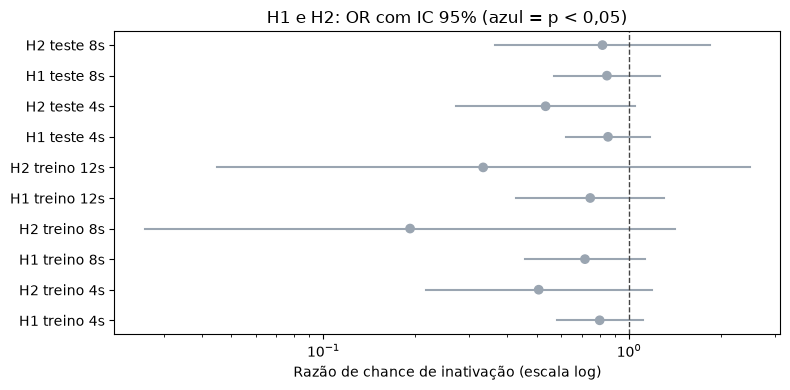

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
s8 = sens.copy(); s8["rotulo"] = s8.hipotese + " " + s8.corte + " " + s8.perf_semanas.astype(str) + "s"
y = np.arange(len(s8))
cores = np.where(s8.p_valor < 0.05, "#1f5f99", "#9aa5b1")
for yi, (o, lo, hi, c) in enumerate(zip(s8.OR, s8.IC95_inf, s8.IC95_sup, cores)):
    ax.plot([lo, hi], [yi, yi], color=c, lw=1.5)
ax.scatter(s8.OR, y, color=cores, zorder=3)
ax.axvline(1, color="#444", lw=1, ls="--")
ax.set_yticks(y, s8.rotulo); ax.set_xscale("log"); ax.set_xlabel("Razão de chance de inativação (escala log)")
ax.set_title("H1 e H2: OR com IC 95% (azul = p < 0,05)")
fig.tight_layout(); fig.savefig(FIG / "03_or_h1_h2.png", dpi=150)

#### 7. Veredito a partir dos resultados

In [9]:
def veredito(h):
    s = sens[sens.hipotese == h]
    principal = s[(s.corte == "treino") & (s.perf_semanas == 8)].iloc[0]
    sig_menor = (s.p_valor < 0.05) & (s.OR < 1)
    if principal.p_valor >= 0.05:
        v = "refutada (sem diferença significativa a 5% na análise principal)"
    elif principal.OR < 1 and sig_menor.all():
        v = "aceita (OR < 1 e p < 0,05 em todos os cortes e janelas)"
    elif principal.OR < 1:
        v = f"aceita parcialmente (OR < 1 e significativa em {int(sig_menor.sum())} de {len(s)} combinações)"
    else:
        v = "refutada (associação significativa no sentido oposto: OR > 1)"
    return {"hipotese": h, "OR_principal": principal.OR, "IC95": [principal.IC95_inf, principal.IC95_sup],
            "p_principal": principal.p_valor, "veredito": v}
NUM["veredito"] = [veredito("H1"), veredito("H2")]
json.dump(NUM, open(REP / "numeros_hipoteses.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
for r in NUM["veredito"]:
    print(f"{r['hipotese']}: OR = {r['OR_principal']} (IC 95% {r['IC95'][0]} a {r['IC95'][1]}; p = {r['p_principal']}) -> {r['veredito']}")
print(f"Moderação (corte {NUM['moderacao_corte']}, exploratória):", [(m['hipotese'], m['OR'], m['p_valor'], m['inativos']) for m in NUM['moderacao_demografia_8s']])
for b in NUM["bruta_treino_8s"]:
    print(f"Bruta {b['variavel']}: inativação {b['inativ_pct_0']}% (não) x {b['inativ_pct_1']}% (sim), p = {b['p_valor']:.2g}")

H1: OR = 0.717 (IC 95% 0.457 a 1.126; p = 0.1484) -> refutada (sem diferença significativa a 5% na análise principal)
H2: OR = 0.192 (IC 95% 0.026 a 1.41; p = 0.1048) -> refutada (sem diferença significativa a 5% na análise principal)
Moderação (corte teste, exploratória): [('H1', np.float64(0.349), np.float64(0.1223), 20), ('H2', np.float64(2.043), np.float64(0.3031), 20)]
Bruta recebeu_campanha: inativação 17.0% (não) x 2.8% (sim), p = 1.2e-33
Bruta resgatou_cupom: inativação 10.0% (não) x 0.3% (sim), p = 6.5e-08
